# Feature extraction

This notebook is my exploration log for feature engineering. I build features for each attempt (one row per user, genuine/impostor label and test) and check their usefulness on simple per-user baseline classifiers, mainly logistic regression, before further model development.

After the EDA I wrote three functions in the `behavioral_ml` package (`src/behavioral_ml`):
- `load_data` (`etl` module): loads all 88 JSON files into two event-level DataFrames, `mouse_df` and `key_df`, indexed by `User ID`, `Is Genuine`, `Test ID` and `Event ID` (`mouse_df` also by `Movement ID`). It drops the columns not needed here and the empty trailing records found in the EDA;
- `add_mouse_kinematics` (`features.mouse` module): calculates kinematics within each mouse movement: step distance, velocity, acceleration and jerk (the third derivative of position);
- `derive_per_movement_features` (`features.mouse` module): aggregates the kinematics to one row per movement.

Sections:
1. Mouse movement features
2. Mouse click and scroll features
3. Keyboard features (first pass)
4. Baseline models
5. Cleaning the keyboard events: one row per physical key press
6. Keyboard features on the cleaned events, and re-evaluation

The cells are kept in the order I worked. The cleaned-up versions of these steps are being moved into `src/behavioral_ml/features/mouse|keyboard.py`, and model evaluation continues in `models.ipynb`.

Let's load the data first using the `load_data` function.

In [1]:
import pandas as pd
import numpy as np

from behavioral_ml.etl import load_data

mouse_df, key_df = load_data("../data/raw_kmt_dataset")

mouse_df.sort_index()

Event  \
User ID Is Genuine Test ID Event ID Movement ID                 
1       False      1       0        1                movement   
                           1        <NA>         left release   
                           2        1                movement   
                           3        1                movement   
                           4        1                movement   
...                                                       ...   
88      True       10      119      4                movement   
                           120      4                movement   
                           121      4                movement   
                           122      4                movement   
                           123      <NA>           left press   

                                                                Coordinates  \
User ID Is Genuine Test ID Event ID Movement ID                               
1       False      1       0        1                         [386.0, 91.0]   
                           1        <NA>         [386.0, 91.00000000000001]   
                           2        1                         [386.0, 92.0]   
                           3        1                         [387.0, 92.0]   
                           4        1                         [387.0, 93.0]   
...                                                                     ...   
88      True       10      119      4                         [387.0, 93.0]   
                           120      4                         [387.0, 92.0]   
                           121      4                         [387.0, 91.0]   
                           122      4                         [386.0, 90.0]   
                           123      <NA>         [386.0, 90.00000000000004]   

                                                             Epoch  
User ID Is Genuine Test ID Event ID Movement ID                     
1       False      1       0        1            1644175528.359473  
                           1        <NA>         1644175528.408747  
                           2        1            1644175528.421404  
                           3        1            1644175528.471485  
                           4        1            1644175528.496569  
...                                                            ...  
88      True       10      119      4            1649930368.457277  
                           120      4            1649930368.469285  
                           121      4            1649930368.481287  
                           122      4            1649930368.493289  
                           123      <NA>         1649930368.959408  

[644405 rows x 3 columns]

## 1. Mouse movement features

`add_mouse_kinematics` splits `Coordinates` into `X` and `Y` and, within each movement (`Movement ID`), takes differences between consecutive `movement` events:
- `dX`, `dY`: change in position (pixels);
- `dS`: distance between consecutive points;
- `dT`: time between consecutive events (seconds);
- `V = dS / dT`: velocity;
- `A = ΔV / dT`: acceleration;
- `Jerk = ΔA / dT`: jerk.

Other event types (clicks, scrolls) get `NaN` in these columns.

In [2]:
from behavioral_ml.features.mouse import add_mouse_kinematics, derive_per_movement_features

movement_features = mouse_df.pipe(add_mouse_kinematics)
movement_features.head()

Event     Coordinates  \
User ID Is Genuine Test ID Event ID Movement ID                             
1       True       1       0        1            movement   [30.0, 581.0]   
                           1        1            movement   [76.0, 569.0]   
                           2        1            movement  [159.0, 549.0]   
                           3        1            movement  [194.0, 540.0]   
                           4        1            movement  [239.0, 531.0]   

                                                             Epoch      X  \
User ID Is Genuine Test ID Event ID Movement ID                             
1       True       1       0        1            1644173827.568144   30.0   
                           1        1            1644173827.580155   76.0   
                           2        1            1644173827.592166  159.0   
                           3        1            1644173827.605178  194.0   
                           4        1             1644173827.61819  239.0   

                                                     Y    dX    dY         dS  \
User ID Is Genuine Test ID Event ID Movement ID                                 
1       True       1       0        1            581.0   NaN   NaN        NaN   
                           1        1            569.0  46.0 -12.0  47.539457   
                           2        1            549.0  83.0 -20.0  85.375641   
                           3        1            540.0  35.0  -9.0  36.138622   
                           4        1            531.0  45.0  -9.0  45.891176   

                                                       dT            V  \
User ID Is Genuine Test ID Event ID Movement ID                          
1       True       1       0        1                <NA>         <NA>   
                           1        1            0.012012  3957.740734   
                           2        1            0.012011  7108.231746   
                           3        1            0.013012  2777.293856   
                           4        1            0.013011  3526.982473   

                                                             A  \
User ID Is Genuine Test ID Event ID Movement ID                  
1       True       1       0        1                     <NA>   
                           1        1                     <NA>   
                           2        1            262304.564712   
                           3        1           -332837.461102   
                           4        1             57617.582781   

                                                            Jerk  
User ID Is Genuine Test ID Event ID Movement ID                   
1       True       1       0        1                       <NA>  
                           1        1                       <NA>  
                           2        1                       <NA>  
                           3        1           -45737335.863801  
                           4        1             30008559.98049

In [3]:
movement_features = movement_features.pipe(derive_per_movement_features)
movement_features.head()

Path  Duration      V_q10  \
User ID Is Genuine Test ID Movement ID                                     
1       False      1       1            1343.113141  4.379695  27.052246   
                           2             738.613262  2.388698  15.789417   
                           4              12.650282  0.808292   3.581197   
                           7             288.162445  1.710045  54.883191   
                           9             127.660290  0.728299  53.858716   

                                          V_median        V_q90     A_min_q20  \
User ID Is Genuine Test ID Movement ID                                          
1       False      1       1            249.859253  1000.277566 -31867.512237   
                           2            388.086299  2372.865641 -72105.226123   
                           4             80.103737   168.297813  -3011.296614   
                           7            211.419948   667.229293 -22892.846446   
                           9            171.937328   559.822676 -31516.951711   

                                          A_plus_q80    Jerk_min_q20  \
User ID Is Genuine Test ID Movement ID                                 
1       False      1       1            30209.760825 -4625682.999418   
                           2            57453.618975 -9637456.795245   
                           4             7631.104061   -685344.30537   
                           7            23136.201083 -3812479.996487   
                           9            29050.206817 -4587431.378334   

                                         Jerk_plus_q80  Displacement  \
User ID Is Genuine Test ID Movement ID                                 
1       False      1       1            4981686.291335    507.575610   
                           2            6729970.160063    670.543809   
                           4             622980.889413     11.401754   
                           7            3099453.628269    149.459024   
                           9            3749538.272634    114.586212   

                                        Straightness       V_avg  
User ID Is Genuine Test ID Movement ID                            
1       False      1       1                0.377910  306.668178  
                           2                0.907842  309.211673  
                           4                0.901304    15.65063  
                           7                0.518662  168.511629  
                           9                0.897587  175.285458

`derive_per_movement_features` aggregates the kinematics to one row per movement. Besides quantiles of velocity (`V_q10`, `V_median`, `V_q90`) and of acceleration and jerk (the 20th percentile of negative values, `A_min_q20` and `Jerk_min_q20`, and the 80th percentile of positive values, `A_plus_q80` and `Jerk_plus_q80`), I have added a few features:
- `Path`: total distance travelled during the movement;
- `Duration`: movement duration;
- `Displacement`: straight-line (L2) distance between the start and end points;
- `Straightness`: `Displacement / Path`, between 0 and 1; the closer to 1, the straighter the movement;
- `V_avg`: average velocity, `Path / Duration`. I prefer it to averaging instantaneous velocities, because event logging isn't perfect: some events are missing and the base interval between events is about 12 ms, so instantaneous values are noisy.

Very short movements (`Path` below 5 pixels, the `min_Path` parameter) are discarded.

Next, I aggregate the per-movement features to one row per attempt. An attempt has only about 7 movements (see the EDA), so for path length and duration I use the median and the IQR, which are less sensitive to a single unusually long movement. At this level, `V_avg` becomes `V_real_mean` and `V_real_std`.

In [4]:
movement_test_level_features = movement_features.groupby(level=["User ID", "Is Genuine", "Test ID"]).agg(
    Path_median = ("Path", "median"),
    Path_iqr = ("Path", lambda x: x.quantile(.75) - x.quantile(.25)),
    Duration_median = ("Duration", "median"),
    Duration_iqr = ("Duration", lambda x: x.quantile(.75) - x.quantile(.25)),
    V_real_mean=("V_avg", "mean"),
    V_real_std=("V_avg", "std"),
    V_q10_mean=("V_q10", "mean"),
    Straightness_mean=("Straightness", "mean"),
    Straightness_std=("Straightness", "std"),
    Straightness_median=("Straightness", "median"),
    A_min_mean=("A_min_q20", "mean"),
    A_plus_mean=("A_plus_q80", "mean"),
    Jerk_min_mean=("Jerk_min_q20", "mean"),
    Jerk_plus_mean=("Jerk_plus_q80", "mean")
)
movement_test_level_features

Path_median    Path_iqr  Duration_median  \
User ID Is Genuine Test ID                                             
1       False      1         288.162445  440.753629         0.808292   
                   2         156.540442  126.153846         1.186481   
                   3         506.975291  390.374930         1.560235   
                   4         147.184662  132.460121         0.715755   
                   5         180.208823  170.316779         0.503478   
...                                 ...         ...              ...   
88      True       6         362.072651  231.827669          0.99775   
                   7         283.018837  171.857896         0.718182   
                   8         296.791224  109.029263         0.806208   
                   9         289.207267  104.604152         0.636165   
                   10        284.718996   86.171983         0.579148   

                            Duration_iqr  V_real_mean  V_real_std  V_q10_mean  \
User ID Is Genuine Test ID                                                      
1       False      1            1.320218   247.238431  183.385716   44.552617   
                   2            0.891805   180.819024   91.076198   54.389009   
                   3             1.10403   332.795623  111.181444   94.278052   
                   4            0.388159   270.479865  108.191208   73.045616   
                   5            0.907254    323.70584  264.607996   83.026475   
...                                  ...          ...         ...         ...   
88      True       6            0.236818    339.77184  142.016136   56.013517   
                   7             0.42211   463.439243    78.06806   46.050862   
                   8            0.281569   299.456443   71.068765   75.783688   
                   9            0.219555   352.796688  102.966834   55.175571   
                   10           0.170542   389.926161   97.628055   63.957618   

                            Straightness_mean  Straightness_std  \
User ID Is Genuine Test ID                                        
1       False      1                 0.621676          0.270673   
                   2                 0.613355          0.239859   
                   3                 0.483614          0.283542   
                   4                 0.747512          0.321127   
                   5                 0.721954          0.321307   
...                                       ...               ...   
88      True       6                 0.558973          0.308117   
                   7                 0.818987          0.283976   
                   8                 0.795741          0.180377   
                   9                 0.844770          0.180421   
                   10                0.852197          0.163107   

                            Straightness_median    A_min_mean   A_plus_mean  \
User ID Is Genuine Test ID                                                    
1       False      1                   0.518662 -35474.536212  29032.348312   
                   2                   0.680645 -21564.360267  23625.258934   
                   3                   0.444299  -38270.97847  37162.957878   
                   4                   0.901379 -24680.760742   22708.88576   
                   5                   0.821403 -34156.522987   104635.3775   
...                                         ...           ...           ...   
88      True       6                   0.621663  -29174.43323  35778.709481   
                   7                   0.975130 -51418.434442  44561.567282   
                   8                   0.898192 -24698.719215  31132.089234   
                   9                   0.926857 -24456.745186  21521.313054   
                   10                  0.928458 -31384.902988  27896.213748   

                             Jerk_min_mean  Jerk_plus_mean  
User ID Is Genuine Test ID                                  
1       False  

## 2. Mouse click and scroll features

Non-movement events are named `<button> <action>`, e.g. `left press`. I split them into `Button` and `Button Event` and count each combination.

In [5]:
df = mouse_df.copy()
click_features = df.loc[df["Event"] != "movement"]
df[["Button", "Button Event"]] = click_features["Event"].str.split(" ", expand=True)
df.groupby(by=["Button", "Button Event"]).count()

Event  Coordinates  Epoch
Button      Button Event                           
left        press         11563        11563  11563
            release       11475        11475  11475
mouse4      press             3            3      3
            release           3            3      3
right       press            71           71     71
            release          71           71     71
scrolldown  press            34           34     34
            release          34           34     34
scrollleft  press             1            1      1
            release           1            1      1
scrollright press            10           10     10
            release          11           11     11
scrollup    press           125          125    125
            release         122          122    122

Left clicks dominate (11,563 presses). Right clicks (71), the side button `mouse4` (3) and scrolling (170 scroll presses) are rare. Presses and releases don't always pair up: there are 88 more `left press` than `left release` events, so pairs have to be matched explicitly rather than assumed.

### Click dwell time

For each button, I take the next event of the same button within the attempt. If a `press` is followed by a `release`, the time between them is the click dwell time, i.e. how long the button was held. Presses without a matching release get `NaN`.

In [6]:
click_features = df.loc[df["Event"] != "movement"]
click_features.groupby([
    pd.Grouper(level="User ID"),
    pd.Grouper(level="Is Genuine"),
    pd.Grouper(level="Test ID"),
    "Button"
    ])[["Button","Button Event"]].shift(0)

Button Button Event
User ID Is Genuine Test ID Event ID Movement ID                    
1       True       1       55       <NA>          left        press
                           56       <NA>          left      release
                           74       <NA>          left        press
                           78       <NA>          left      release
                           83       <NA>          left        press
...                                                ...          ...
88      False      10      159      <NA>          left        press
                           160      <NA>          left      release
                           191      <NA>          left        press
                           192      <NA>          left      release
                           294      <NA>          left        press

[23524 rows x 2 columns]

In [7]:
MOUSE_BUTTONS = ["left", "right", "mouse4"]

button_features = df.loc[(df["Event"] != "movement") & df["Button"].isin(MOUSE_BUTTONS)]
g = button_features.groupby([
    pd.Grouper(level="User ID"),
    pd.Grouper(level="Is Genuine"),
    pd.Grouper(level="Test ID"),
    "Button"
    ])
button_features["Next Button Event"] = g["Button Event"].shift(-1)
button_features["Next Epoch"] = g["Epoch"].shift(-1)

valid_press = (button_features["Button Event"] == "press") & (button_features["Next Button Event"] == "release")
button_features["Dwell Time"] = np.where(valid_press, button_features["Next Epoch"] - button_features["Epoch"], np.nan)
button_features

Event  \
User ID Is Genuine Test ID Event ID Movement ID                 
1       True       1       55       <NA>           left press   
                           56       <NA>         left release   
                           74       <NA>           left press   
                           78       <NA>         left release   
                           83       <NA>           left press   
...                                                       ...   
88      False      10      159      <NA>           left press   
                           160      <NA>         left release   
                           191      <NA>           left press   
                           192      <NA>         left release   
                           294      <NA>           left press   

                                                                 Coordinates  \
User ID Is Genuine Test ID Event ID Movement ID                                
1       True       1       55       <NA>         [307.0, 383.00000000000006]   
                           56       <NA>         [307.0, 383.00000000000006]   
                           74       <NA>                      [318.0, 312.0]   
                           78       <NA>                      [319.0, 305.0]   
                           83       <NA>                      [324.0, 291.0]   
...                                                                      ...   
88      False      10      159      <NA>         [422.0, 380.99999999999994]   
                           160      <NA>         [422.0, 380.99999999999994]   
                           191      <NA>                      [288.0, 285.0]   
                           192      <NA>                      [288.0, 285.0]   
                           294      <NA>          [376.0, 88.99999999999999]   

                                                             Epoch Button  \
User ID Is Genuine Test ID Event ID Movement ID                             
1       True       1       55       <NA>         1644173828.782241   left   
                           56       <NA>         1644173828.856247   left   
                           74       <NA>         1644173829.122411   left   
                           78       <NA>         1644173829.186461   left   
                           83       <NA>         1644173829.428797   left   
...                                                            ...    ...   
88      False      10      159      <NA>         1649151715.149565   left   
                           160      <NA>         1649151715.375268   left   
                           191      <NA>         1649151718.584617   left   
                           192      <NA>         1649151718.812721   left   
                           294      <NA>         1649151788.412875   left   

                                                Button Event  \
User ID Is Genuine Test ID Event ID Movement ID                
1       True       1       55       <NA>               press   
                           56       <NA>             release   
                           74       <NA>               press   
                           78       <NA>             release   
                           83       <NA>               press   
...                                                      ...   
88      False      10      159      <NA>               press   
                           160      <NA>             release   
                           191      <NA>               press   
                           192      <NA>             release   
                           294      <NA>               press   

                                                Next Button Event  \
User ID Is Genuine Test ID Event ID Movement ID                     
1       True       1       55       <NA>                  release   
                           56       <NA>                    press   
                           74       <NA>                  

### Scroll bursts

A single turn of the scroll wheel produces a series of `scrollup`/`scrolldown` `press` events, one per notch. To count scrolling *actions* rather than notches, I look at the time between consecutive scroll presses within an attempt (`Interscroll Time`).

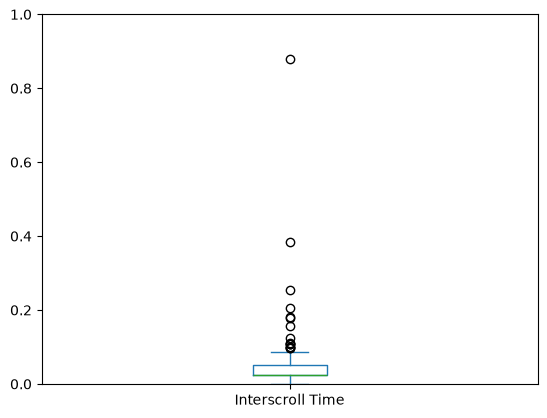

In [8]:
SCROLL_TYPES = [
    "scrollup",
    "scrolldown"
]
LEVELS = [
    "User ID",
    "Is Genuine",
    "Test ID"
]


scroll = df.loc[df["Button"].isin(SCROLL_TYPES) & df["Button Event"].eq("press") & (df["Event"] != "movement")]
g = scroll.groupby(level=LEVELS)

scroll["Interscroll Time"] = g["Epoch"].diff()
ax = scroll["Interscroll Time"].plot(kind="box")
ax.set_ylim(ymin=0, ymax=1);

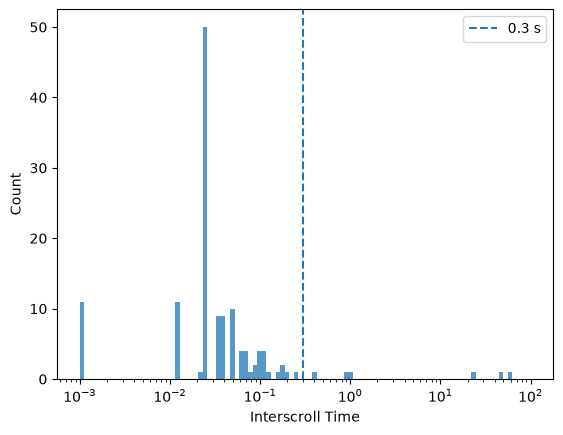

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

bins = np.logspace(
    np.log10(0.001),
    np.log10(100),
    100,
)

sns.histplot(scroll["Interscroll Time"], bins=bins)
plt.xscale("log")

plt.axvline(0.3, linestyle="--", label="0.3 s")

plt.legend();

On the log scale, most intervals are below 0.1 s, with the highest peak at about 25 ms: these are notches within one scroll. Only a handful of gaps are longer than 0.3 s, and they separate distinct scroll actions. So I use 0.3 s as the threshold: a new burst starts at the first scroll press of an attempt and after every gap longer than 0.3 s.

In [10]:
threshold = 0.3

scroll["New Burst"] = (
    scroll["Interscroll Time"].isna()
    | scroll["Interscroll Time"].gt(threshold)
)

scroll["Burst ID"] = (
    scroll.groupby(level=LEVELS, sort=False)["New Burst"]
    .cumsum()
)

scroll

Event  \
User ID Is Genuine Test ID Event ID Movement ID                     
2       False      9       352      <NA>         scrolldown press   
                           360      <NA>         scrolldown press   
                           371      <NA>         scrolldown press   
3       False      9       247      <NA>         scrolldown press   
                           249      <NA>         scrolldown press   
...                                                           ...   
88      True       1       91       <NA>           scrollup press   
                           93       <NA>           scrollup press   
                           97       <NA>           scrollup press   
                           99       <NA>           scrollup press   
                           103      <NA>           scrollup press   

                                                                 Coordinates  \
User ID Is Genuine Test ID Event ID Movement ID                                
2       False      9       352      <NA>          [219.0, 93.00000000000003]   
                           360      <NA>         [332.0, 146.00000000000003]   
                           371      <NA>         [434.0, 136.99999999999997]   
3       False      9       247      <NA>          [277.0, 91.99999999999999]   
                           249      <NA>          [277.0, 91.99999999999999]   
...                                                                      ...   
88      True       1       91       <NA>         [492.99999999999994, 556.0]   
                           93       <NA>         [492.99999999999994, 556.0]   
                           97       <NA>         [492.99999999999994, 556.0]   
                           99       <NA>         [492.99999999999994, 556.0]   
                           103      <NA>         [492.99999999999994, 556.0]   

                                                             Epoch  \
User ID Is Genuine Test ID Event ID Movement ID                      
2       False      9       352      <NA>         1644185645.628699   
                           360      <NA>         1644185645.702723   
                           371      <NA>          1644185645.81218   
3       False      9       247      <NA>         1644185679.179201   
                           249      <NA>         1644185679.204164   
...                                                            ...   
88      True       1       91       <NA>         1649929693.672558   
                           93       <NA>         1649929693.696567   
                           97       <NA>         1649929693.721573   
                           99       <NA>         1649929693.773583   
                           103      <NA>          1649929693.79859   

                                                     Button Button Event  \
User ID Is Genuine Test ID Event ID Movement ID                            
2       False      9       352      <NA>         scrolldown        press   
                           360      <NA>         scrolldown        press   
                           371      <NA>         scrolldown        press   
3       False      9       247      <NA>         scrolldown        press   
                           249      <NA>         scrolldown        press   
...                                                     ...          ...   
88      True       1       91       <NA>           scrollup        press   
                           93       <NA>           scrollup        press   
                           97       <NA>           scrollup        press   
                           99       <NA>           scrollup        press   
                           103      <NA>           scrollup        press   

                                                 Interscroll Time  New Burst  \
User ID Is Genuine Test ID Event ID Movement ID                                
2       False      9       352      <NA>                     

I join the scroll bursts and click dwell times back to the mouse events and aggregate them per attempt:
- `Burst_count`: number of scroll bursts;
- `Dwell_Time_mean`, `Dwell_Time_std`: mean and standard deviation of click dwell time;
- `Click_count`: number of clicks with a valid dwell time.

Attempts without scrolling get 0 bursts, and missing click statistics are filled with 0. Scrolling is rare (see the counts above), so `Burst_count` is 0 for most attempts.

In [11]:
mouse_df = (df
            .join(scroll[["Interscroll Time", "Burst ID"]])
            .join(button_features["Dwell Time"])
            )

In [12]:
test_level_clicks = mouse_df.groupby(level=LEVELS).agg(
    Burst_count=("Burst ID", "max"),
    Dwell_Time_mean=("Dwell Time", "mean"),
    Dwell_Time_std=("Dwell Time", "std"),
    Click_count=("Dwell Time", "count")
)
test_level_clicks.fillna(0, inplace=True)

Burst_count  Dwell_Time_mean  Dwell_Time_std  \
User ID Is Genuine Test ID                                                 
1       False      1                  0         0.102698        0.021886   
                   2                  0         0.133980        0.010070   
                   3                  0         0.095714        0.019424   
                   4                  0         0.220024        0.010642   
                   5                  0         0.167220        0.046395   
...                                 ...              ...             ...   
88      True       6                  0         0.227391        0.002516   
                   7                  0         0.229058        0.001411   
                   8                  0         0.224055        0.008493   
                   9                  0         0.217556        0.000707   
                   10                 0         0.223543        0.010595   

                            Click_count  
User ID Is Genuine Test ID               
1       False      1                  6  
                   2                  6  
                   3                  5  
                   4                  6  
                   5                  3  
...                                 ...  
88      True       6                  3  
                   7                  2  
                   8                  2  
                   9                  2  
                   10                 2  

[1760 rows x 4 columns]

## 3. Keyboard features (first pass)

After `load_data`, `key_df` has one row per raw key event: the `Key`, the `Event` (`pressed` or `released`) and its `Epoch`.

In [13]:
key_df.head()

Key     Event              Epoch
User ID Is Genuine Test ID Event ID                                    
1       True       1       0         shift   pressed   1644173829.98174
                           1             m   pressed  1644173830.121021
                           2         shift  released   1644173830.16947
                           3             m  released   1644173830.21818
                           4             r   pressed  1644173830.293582

In [14]:
key_df["Key"].unique()

<ArrowStringArray>
[          'shift',               'm',               'r',               's',
        'spacebar',               'w',               'e',       'backspace',
               'l',               'i',             'tab',               '4',
               '2',               '8',               '9',               '1',
               '5',               '0',               '6',               '7',
               '3',          'rshift',         'numpad4',         'numpad2',
         'numpad8',         'numpad9',         'numpad1',         'numpad5',
         'numpad0',         'numpad6',         'numpad7',         'numpad3',
        'capslock', 'numpadsubstract',               '.',               'j',
               ',',               'h',               'd',               't',
               'a',               'y',               'u',               'o',
         'numlock',               'f',           'enter',               'n',
               'g',               '-',               '`',

I group the keys that reflect typing habits: numpad keys (every key whose name starts with `num`, so `numlock` is included), arrow keys, correction keys (`delete`, `backspace`) and the two shift keys.

In [15]:
NUMPAD_KEYS = [key for key in key_df["Key"].unique() if key.startswith("num")]

ARROW_KEYS = ["up", "down", "right", "left"]
CORRECTION_KEYS = ["delete", "backspace"]
SHIFT_KEYS = ["shift", "rshift"]

### Dwell time (naive)

For each key except the shift keys, I take the next event of the same key within the attempt. If a `pressed` event is followed by a `released` one, the time between them is the dwell time. Shift keys are excluded because they are often held down for a long time (see the EDA).

With auto-repeat, only the last repeated press is paired with the release, so the dwell time of a held key is underestimated. Section 5 fixes this.

In [16]:
shiftless_key_df = key_df.loc[~key_df["Key"].isin(SHIFT_KEYS)]
g = shiftless_key_df.groupby([
    pd.Grouper(level="User ID"),
    pd.Grouper(level="Is Genuine"),
    pd.Grouper(level="Test ID"),
    "Key"
    ])
key_df["Next Event"] = g["Event"].shift(-1)
key_df["Next Epoch"] = g["Epoch"].shift(-1)

valid_press = (key_df["Event"] == "pressed") & (key_df["Next Event"] == "released")
key_df["Dwell Time"] = np.where(valid_press, key_df["Next Epoch"] - key_df["Epoch"], np.nan)
key_df

Key     Event              Epoch  \
User ID Is Genuine Test ID Event ID                                       
1       True       1       0         shift   pressed   1644173829.98174   
                           1             m   pressed  1644173830.121021   
                           2         shift  released   1644173830.16947   
                           3             m  released   1644173830.21818   
                           4             r   pressed  1644173830.293582   
...                                    ...       ...                ...   
88      False      10      78            2   pressed  1649151779.791193   
                           79            2  released  1649151779.888461   
                           80            3   pressed  1649151780.045138   
                           81            3  released  1649151780.156547   
                           82          tab  released  1649151787.129236   

                                    Next Event         Next Epoch  Dwell Time  
User ID Is Genuine Test ID Event ID                                            
1       True       1       0               NaN               <NA>         NaN  
                           1          released   1644173830.21818    0.097159  
                           2               NaN               <NA>         NaN  
                           3           pressed  1644173832.633649         NaN  
                           4          released  1644173830.355541    0.061959  
...                                        ...                ...         ...  
88      False      10      78         released  1649151779.888461    0.097268  
                           79              NaN               <NA>         NaN  
                           80         released  1649151780.156547    0.111409  
                           81              NaN               <NA>         NaN  
                           82              NaN               <NA>         NaN  

[172563 rows x 6 columns]

### Flight time (naive)

Next, the time from each key press (shift excluded) to the next key press in the attempt. Strictly speaking, this is the press-to-press latency (`DD` in section 6), not the flight time used in the paper (from a release to the next press). It also includes the pauses between form fields.

In [17]:
shiftless_key_df = key_df.loc[(~key_df["Key"].isin(SHIFT_KEYS)) & (key_df["Event"] == "pressed")]
g = shiftless_key_df.groupby([
    pd.Grouper(level="User ID"),
    pd.Grouper(level="Is Genuine"),
    pd.Grouper(level="Test ID"),
    ])
key_df["Next Pressed Key"] = g["Key"].shift(-1)
key_df["Next Pressed Epoch"] = g["Epoch"].shift(-1)

key_df["Flight Time"] = key_df["Next Pressed Epoch"] - key_df["Epoch"]
key_df

Key     Event              Epoch  \
User ID Is Genuine Test ID Event ID                                       
1       True       1       0         shift   pressed   1644173829.98174   
                           1             m   pressed  1644173830.121021   
                           2         shift  released   1644173830.16947   
                           3             m  released   1644173830.21818   
                           4             r   pressed  1644173830.293582   
...                                    ...       ...                ...   
88      False      10      78            2   pressed  1649151779.791193   
                           79            2  released  1649151779.888461   
                           80            3   pressed  1649151780.045138   
                           81            3  released  1649151780.156547   
                           82          tab  released  1649151787.129236   

                                    Next Event         Next Epoch  Dwell Time  \
User ID Is Genuine Test ID Event ID                                             
1       True       1       0               NaN               <NA>         NaN   
                           1          released   1644173830.21818    0.097159   
                           2               NaN               <NA>         NaN   
                           3           pressed  1644173832.633649         NaN   
                           4          released  1644173830.355541    0.061959   
...                                        ...                ...         ...   
88      False      10      78         released  1649151779.888461    0.097268   
                           79              NaN               <NA>         NaN   
                           80         released  1649151780.156547    0.111409   
                           81              NaN               <NA>         NaN   
                           82              NaN               <NA>         NaN   

                                    Next Pressed Key  Next Pressed Epoch  \
User ID Is Genuine Test ID Event ID                                        
1       True       1       0                     NaN                <NA>   
                           1                       r   1644173830.293582   
                           2                     NaN                <NA>   
                           3                     NaN                <NA>   
                           4                       s   1644173830.480926   
...                                              ...                 ...   
88      False      10      78                      3   1649151780.045138   
                           79                    NaN                <NA>   
                           80                    NaN                <NA>   
                           81                    NaN                <NA>   
                           82                    NaN                <NA>   

                                     Flight Time  
User ID Is Genuine Test ID Event ID               
1       True       1       0                <NA>  
                           1            0.172561  
                           2                <NA>  
                           3                <NA>  
                           4            0.187344  
...                                          ...  
88      False      10      78           0.253945  
                           79               <NA>  
                           80               <NA>  
                           81               <NA>  
                           82               <NA>  

[172563 rows x 9 columns]

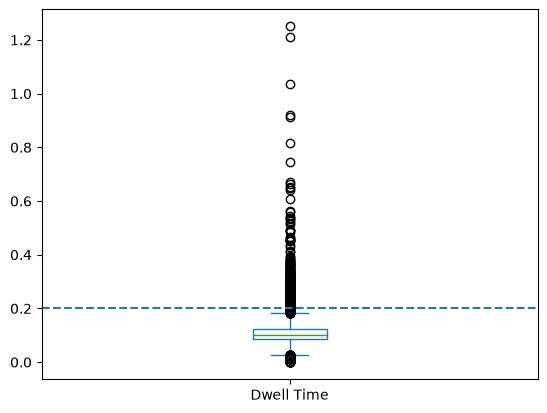

In [18]:
ax = key_df["Dwell Time"].plot(kind="box")
plt.axhline(0.2, linestyle="--", label="0.3 s");

In [19]:
threshold = 0.3

key_df[key_df["Dwell Time"] > threshold]["Key"].value_counts()

Key
lctrl        24
capslock      7
6             7
7             7
4             7
1             6
rctrl         6
enter         6
8             5
-             5
backspace     4
2             4
l             3
spacebar      3
numpad2       2
i             2
right         2
a             2
left          2
9             2
k             1
numpad9       1
numpad3       1
m             1
s             1
3             1
h             1
numpad6       1
g             1
0             1
n             1
'             1
super         1
alt           1
z             1
Name: count, dtype: int64

Most dwell times are around 0.1 s (the middle half lies between about 0.085 and 0.125 s), with a long tail of outliers. The keys most often held longer than 0.3 s are `lctrl`, followed by `capslock`, some digits, `rctrl` and `enter`.

In [20]:
key_df

Key     Event              Epoch  \
User ID Is Genuine Test ID Event ID                                       
1       True       1       0         shift   pressed   1644173829.98174   
                           1             m   pressed  1644173830.121021   
                           2         shift  released   1644173830.16947   
                           3             m  released   1644173830.21818   
                           4             r   pressed  1644173830.293582   
...                                    ...       ...                ...   
88      False      10      78            2   pressed  1649151779.791193   
                           79            2  released  1649151779.888461   
                           80            3   pressed  1649151780.045138   
                           81            3  released  1649151780.156547   
                           82          tab  released  1649151787.129236   

                                    Next Event         Next Epoch  Dwell Time  \
User ID Is Genuine Test ID Event ID                                             
1       True       1       0               NaN               <NA>         NaN   
                           1          released   1644173830.21818    0.097159   
                           2               NaN               <NA>         NaN   
                           3           pressed  1644173832.633649         NaN   
                           4          released  1644173830.355541    0.061959   
...                                        ...                ...         ...   
88      False      10      78         released  1649151779.888461    0.097268   
                           79              NaN               <NA>         NaN   
                           80         released  1649151780.156547    0.111409   
                           81              NaN               <NA>         NaN   
                           82              NaN               <NA>         NaN   

                                    Next Pressed Key  Next Pressed Epoch  \
User ID Is Genuine Test ID Event ID                                        
1       True       1       0                     NaN                <NA>   
                           1                       r   1644173830.293582   
                           2                     NaN                <NA>   
                           3                     NaN                <NA>   
                           4                       s   1644173830.480926   
...                                              ...                 ...   
88      False      10      78                      3   1649151780.045138   
                           79                    NaN                <NA>   
                           80                    NaN                <NA>   
                           81                    NaN                <NA>   
                           82                    NaN                <NA>   

                                     Flight Time  
User ID Is Genuine Test ID Event ID               
1       True       1       0                <NA>  
                           1            0.172561  
                           2                <NA>  
                           3                <NA>  
                           4            0.187344  
...                                          ...  
88      False      10      78           0.253945  
                           79               <NA>  
                           80               <NA>  
                           81               <NA>  
                           82               <NA>  

[172563 rows x 9 columns]

### Habit counts

Per attempt, I count the presses of keys that reflect habits rather than typing speed:
- `capslock`, `enter` and `spacebar`;
- arrow keys (summed);
- correction keys, `backspace` and `delete`;
- numpad keys (summed);
- `tab`, counted on `released` events, because its presses are almost never logged (see the EDA).

These counts use the raw events, so a key held long enough to auto-repeat is counted several times.

In [21]:
pressed_key_df = key_df[(key_df["Event"] == "pressed") & key_df["Key"].isin(["capslock", "enter", "spacebar"])]
other_keys_test_level = pressed_key_df.groupby([
    pd.Grouper(level="User ID"),
    pd.Grouper(level="Is Genuine"),
    pd.Grouper(level="Test ID"),
    "Key"
    ])["Event"].count().unstack()

In [22]:
arrow_key_df = key_df[(key_df["Event"] == "pressed") & key_df["Key"].isin(ARROW_KEYS)]
arrow_keys_test_level = arrow_key_df.groupby([
    pd.Grouper(level="User ID"),
    pd.Grouper(level="Is Genuine"),
    pd.Grouper(level="Test ID"),
    "Key"
    ])["Event"].count().unstack()
arrow_keys_test_level = arrow_keys_test_level.sum(axis=1).rename("arrows").astype("int")

In [23]:
correction_key_df = key_df[(key_df["Event"] == "pressed") & key_df["Key"].isin(CORRECTION_KEYS)]
correction_keys_test_level = correction_key_df.groupby([
    pd.Grouper(level="User ID"),
    pd.Grouper(level="Is Genuine"),
    pd.Grouper(level="Test ID"),
    "Key"
    ])["Event"].count().unstack()

In [24]:
numpad_key_df = key_df[(key_df["Event"] == "pressed") & key_df["Key"].isin(NUMPAD_KEYS)]
numpad_keys_test_level = numpad_key_df.groupby([
    pd.Grouper(level="User ID"),
    pd.Grouper(level="Is Genuine"),
    pd.Grouper(level="Test ID"),
    "Key"
    ])["Event"].count().unstack()
numpad_keys_test_level = numpad_keys_test_level.sum(axis=1).rename("numpad").astype("int")

In [25]:
released_key_df = key_df[(key_df["Event"] == "released") & key_df["Key"].isin(["tab"])]
tab_test_level = released_key_df.groupby([
    pd.Grouper(level="User ID"),
    pd.Grouper(level="Is Genuine"),
    pd.Grouper(level="Test ID"),
    "Key"
    ])["Event"].count().unstack()

Only 901 of the 1,760 attempts contain a `tab` release, so the use of `tab` for moving between fields varies a lot between attempts. That makes it a promising habit feature, as suggested in the EDA.

### Attempt-level keyboard timing

Mean and standard deviation of dwell and flight time per attempt.

In [26]:
key_test_level = key_df.groupby(level=LEVELS).agg(
    Dwell_mean=("Dwell Time", "mean"),
    Dwell_std=("Dwell Time", "std"),
    Flight_mean=("Flight Time", "mean"),
    Flight_std=("Flight Time", "std")
)

### Feature table

I join all feature families into one table with one row per attempt (88 users × 20 attempts = 1,760 rows) and 30 features. A missing count means the key wasn't pressed in that attempt, so counts are filled with 0.

In [27]:
test_level_features = (
    movement_test_level_features
    .join(test_level_clicks)
    .join(key_test_level)
    .join(other_keys_test_level)
    .join(tab_test_level)
    .join(correction_keys_test_level)
    .join(numpad_keys_test_level)
    .join(arrow_keys_test_level)
)

In [28]:
test_level_features.fillna({
    "enter": 0,
    "spacebar": 0,
    "tab": 0,
    "capslock": 0,
    "arrows": 0,
    "numpad": 0,
    "delete": 0,
    "backspace": 0
}, inplace=True)

Path_median    Path_iqr  Duration_median  \
User ID Is Genuine Test ID                                             
1       False      1         288.162445  440.753629         0.808292   
                   2         156.540442  126.153846         1.186481   
                   3         506.975291  390.374930         1.560235   
                   4         147.184662  132.460121         0.715755   
                   5         180.208823  170.316779         0.503478   
...                                 ...         ...              ...   
88      True       6         362.072651  231.827669          0.99775   
                   7         283.018837  171.857896         0.718182   
                   8         296.791224  109.029263         0.806208   
                   9         289.207267  104.604152         0.636165   
                   10        284.718996   86.171983         0.579148   

                            Duration_iqr  V_real_mean  V_real_std  V_q10_mean  \
User ID Is Genuine Test ID                                                      
1       False      1            1.320218   247.238431  183.385716   44.552617   
                   2            0.891805   180.819024   91.076198   54.389009   
                   3             1.10403   332.795623  111.181444   94.278052   
                   4            0.388159   270.479865  108.191208   73.045616   
                   5            0.907254    323.70584  264.607996   83.026475   
...                                  ...          ...         ...         ...   
88      True       6            0.236818    339.77184  142.016136   56.013517   
                   7             0.42211   463.439243    78.06806   46.050862   
                   8            0.281569   299.456443   71.068765   75.783688   
                   9            0.219555   352.796688  102.966834   55.175571   
                   10           0.170542   389.926161   97.628055   63.957618   

                            Straightness_mean  Straightness_std  \
User ID Is Genuine Test ID                                        
1       False      1                 0.621676          0.270673   
                   2                 0.613355          0.239859   
                   3                 0.483614          0.283542   
                   4                 0.747512          0.321127   
                   5                 0.721954          0.321307   
...                                       ...               ...   
88      True       6                 0.558973          0.308117   
                   7                 0.818987          0.283976   
                   8                 0.795741          0.180377   
                   9                 0.844770          0.180421   
                   10                0.852197          0.163107   

                            Straightness_median  ...  Flight_mean  Flight_std  \
User ID Is Genuine Test ID                       ...                            
1       False      1                   0.518662  ...     0.587801    0.753984   
                   2                   0.680645  ...     0.906589    0.986329   
                   3                   0.444299  ...     0.583382    0.797085   
                   4                   0.901379  ...     0.970226    1.249153   
                   5                   0.821403  ...      0.53398    0.699677   
...                                         ...  ...          ...         ...   
88      True       6                   0.621663  ...      0.84584    0.779117   
                   7                   0.975130  ...     0.901577    0.786469   
                   8                   0.898192  ...     0.831604    0.732379   
                   9                   0.926857  ...     0.992893    0.827139   
                   10                  0.928458  ...     0.826998     0.69335   

                            capslock  enter  spacebar  tab  backspace  delete  \
User ID Is Genuine Test ID    

## 4. Baseline models

The task is verification: for a given card, decide whether an attempt was typed by the card's owner (genuine) or by someone else (impostor). As in the paper, I train one model per user on the 20 attempts on that user's card: `X[u]` holds the features and `y[u]` the `Is Genuine` labels (10 genuine, 10 impostor).

In [29]:
X = [test_level_features.loc[(user_id)] for user_id in range(1, 89)]
y = [test_level_features.loc[(user_id)].index.get_level_values("Is Genuine") for user_id in range(1, 89)]

First, a quick comparison of models on a single stratified train/test split per user, scored by accuracy and averaged over the 88 users. For reference, the paper reports a mean accuracy of 75.85% for a default decision tree on three features (average dwell time, flight time and mouse trajectory length) with a stratified 80/20 split.

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.impute import SimpleImputer

model = DecisionTreeClassifier()

scores = []
for user_id in range(1,89):
    X_train, X_test, y_train, y_test = train_test_split(X[user_id-1], y[user_id-1], stratify=y[user_id-1], test_size=.2, random_state=42)

    model.fit(X_train, y_train)
    scores.append(model.score(X_test, y_test))

np.mean(scores), np.std(scores)

(np.float64(0.8096590909090909), np.float64(0.18842317498625485))

In [31]:
model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression()
)

scores = []
for user_id in range(1,89):
    X_train, X_test, y_train, y_test = train_test_split(X[user_id-1], y[user_id-1], stratify=y[user_id-1], test_size=.2, random_state=42)

    model.fit(X_train, y_train)
    scores.append(model.score(X_test, y_test))

np.mean(scores), np.std(scores)

(np.float64(0.8977272727272727), np.float64(0.14903269373413638))

In [32]:
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('simpleimputer', ...), ('standardscaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['Path_median','Path_iqr','Duration_median',...,'delete','numpad','arrows']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_va

In [33]:
import xgboost as xgb

model = xgb.XGBClassifier(max_depth=2)

scores = []
for user_id in range(1,89):
    X_train, X_test, y_train, y_test = train_test_split(X[user_id-1], y[user_id-1], stratify=y[user_id-1], test_size=.2, random_state=42)

    model.fit(X_train, y_train)
    scores.append(model.score(X_test, y_test))

np.mean(scores), np.std(scores)

(np.float64(0.8607954545454546), np.float64(0.18409003226502743))

In [34]:
model.feature_importances_

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32)

In [35]:
model.feature_names_in_

array(['Path_median', 'Path_iqr', 'Duration_median', 'Duration_iqr',
       'V_real_mean', 'V_real_std', 'V_q10_mean', 'Straightness_mean',
       'Straightness_std', 'Straightness_median', 'A_min_mean',
       'A_plus_mean', 'Jerk_min_mean', 'Jerk_plus_mean', 'Burst_count',
       'Dwell_Time_mean', 'Dwell_Time_std', 'Click_count', 'Dwell_mean',
       'Dwell_std', 'Flight_mean', 'Flight_std', 'capslock', 'enter',
       'spacebar', 'tab', 'backspace', 'delete', 'numpad', 'arrows'],
      dtype='<U19')

The last fitted XGBoost model (user 88) puts all of its importance on a single feature, `Dwell_mean` (index 18). With only 16 training attempts, one split can be enough to separate the classes, so per-user importances shouldn't be over-interpreted.

In [36]:
from sklearn.svm import SVC

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    SVC(kernel="rbf", gamma="auto", C=1),
)

scores = []
for user_id in range(1,89):
    X_train, X_test, y_train, y_test = train_test_split(X[user_id-1], y[user_id-1], stratify=y[user_id-1], test_size=.2, random_state=42)

    model.fit(X_train, y_train)
    scores.append(model.score(X_test, y_test))

np.mean(scores), np.std(scores)

(np.float64(0.8721590909090909), np.float64(0.176753866253435))

Single-split results (mean ± std of per-user accuracy):

| Model | Test size | Accuracy |
|---|---|---|
| Decision tree | 20% | 0.805 ± 0.193 |
| Logistic regression | 20% | 0.898 ± 0.149 |
| XGBoost (`max_depth=2`) | 20% | 0.861 ± 0.184 |
| SVC (RBF, `gamma="auto"`) | 20% | 0.872 ± 0.177 |

These numbers are noisy: each user has only 5 test attempts, so one misclassified attempt changes that user's accuracy by 20 percentage points. The test size also differs between models. Cross-validation gives a more reliable comparison.

### Cross-validation

Stratified 5-fold cross-validation per user: each attempt is used for testing exactly once, and the user's score is the mean over the folds.

In [37]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(C=1),
)

scores = []
for user_id in range(1,89):
    score = cross_val_score(
        model,
        X[user_id-1],
        y[user_id-1],
        cv=cv,
        n_jobs=1
    )
    scores.append(score.mean())

np.mean(scores), np.std(scores)

(np.float64(0.8420454545454544), np.float64(0.09441397107358791))

In [38]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    SVC(kernel="rbf", gamma="auto", C=1),
)

scores = []
for user_id in range(1,89):
    score = cross_val_score(
        model,
        X[user_id-1],
        y[user_id-1],
        cv=cv,
        n_jobs=1
    )
    scores.append(score.mean())

np.mean(scores), np.std(scores)

(np.float64(0.8301136363636363), np.float64(0.08743171774931018))

Cross-validated results (mean ± std of per-user accuracy):

| Model | Accuracy |
|---|---|
| Logistic regression | 0.842 ± 0.094 |
| SVC (RBF, `gamma="auto"`) | 0.830 ± 0.087 |

The cross-validated estimates are lower than the single-split ones, but their spread across users is much smaller. Logistic regression remains the best simple baseline. It is above the paper's 75.85%, although the comparison isn't like-for-like (different split, many more features).

## 5. Cleaning the keyboard events

For further improvement, the keyboard events have to be cleaned and transformed properly. The naive timings above pair raw events, so they are distorted by the logging quirks found in the EDA: a key held down is logged as a series of `pressed` events, and `tab` is logged (almost) only on release.

So I transform the raw events into **one row per physical key press**. `transform_key_events` is applied to the events of each attempt (`groupby(...).apply`) and goes through them in time order:
- the first `pressed` event of a key opens a press and sets its `Down` time;
- further `pressed` events of a key that is already down are treated as repeats and only collected in `Epochs`;
- the `released` event closes the press and sets its `Up` time;
- a `released` event without a preceding press (typically `tab`) becomes a press with `Down` set to the release time, no `Up` and `Release Only = True`;
- presses that are never released are kept without an `Up` time.

In [39]:
def transform_key_events(group):
    presses = []
    active_presses = {}
    for key, event, epoch in group[["Key", "Event", "Epoch"]].itertuples(index=False):
        if (event == "pressed") and (key not in active_presses):
            active_presses[key] = {
                "Key": key,
                "Down": epoch,
                "Epochs": [epoch]
            }
        elif (event == "released") and (key in active_presses):
            active_presses[key]["Up"] = epoch
            presses.append(active_presses.pop(key))
        elif (event == "pressed") and (key in active_presses):
            active_presses[key]["Epochs"].append(epoch)
        elif (event == "released") and (key not in active_presses):
            presses.append({
                "Key": key,
                "Down": epoch,
                "Epochs": [epoch],
                "Release Only": True
            })
    
    presses += active_presses.values()
    presses = sorted(presses, key=lambda x: x["Down"])

    presses = pd.DataFrame(presses)
    return presses
    

key_df = key_df.groupby(level=LEVELS).apply(transform_key_events)
key_df

Key          Down                Epochs  \
User ID Is Genuine Test ID                                                    
1       False      1       0      shift  1.644176e+09  [1644175533.9525526]   
                           1          m  1.644176e+09  [1644175534.0420332]   
                           2          r  1.644176e+09   [1644175534.257084]   
                           3          s  1.644176e+09  [1644175534.4087963]   
                           4   spacebar  1.644176e+09  [1644175534.5358133]   
...                                 ...           ...                   ...   
88      True       10      41         1  1.649930e+09  [1649930364.1611965]   
                           42         0  1.649930e+09   [1649930364.882375]   
                           43       tab  1.649930e+09   [1649930366.013663]   
                           44         2  1.649930e+09  [1649930366.3227415]   
                           45         3  1.649930e+09   [1649930366.718838]   

                                         Up Release Only  
User ID Is Genuine Test ID                                
1       False      1       0   1.644176e+09          NaN  
                           1   1.644176e+09          NaN  
                           2   1.644176e+09          NaN  
                           3   1.644176e+09          NaN  
                           4   1.644176e+09          NaN  
...                                     ...          ...  
88      True       10      41  1.649930e+09          NaN  
                           42  1.649930e+09          NaN  
                           43           NaN         True  
                           44  1.649930e+09          NaN  
                           45  1.649930e+09          NaN  

[84955 rows x 5 columns]

### Are the repeated presses auto-repeat?

If the repeated `pressed` events come from the operating system's key auto-repeat, the first repeat should follow the initial press after a fixed *repeat delay*, and further repeats should come at a fixed *repeat rate*. First, the time until the second press, for every press with repeats:

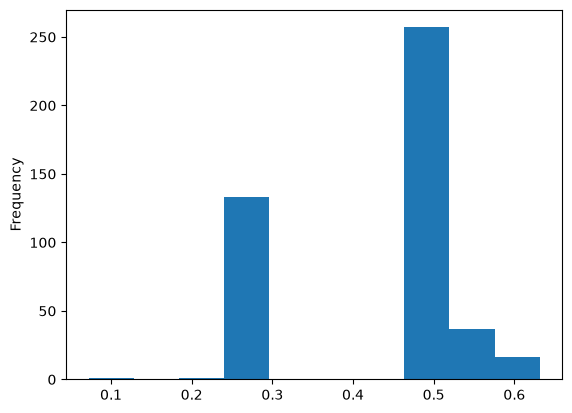

In [40]:
prolonged_key_df = key_df[key_df["Epochs"].transform(lambda x: len(x)>1)]
time_until_second_press = prolonged_key_df["Epochs"].transform(lambda x: x[1] - x[0]).rename("Time Until Second Press")

prolonged_key_df = prolonged_key_df.join(time_until_second_press)
prolonged_key_df["Time Until Second Press"].plot(kind="hist");

The time until the second press forms two tight clusters, at about 0.25–0.3 s and about 0.5 s, with almost nothing below 0.25 s. That looks like a fixed repeat delay rather than deliberate double presses. Both values match standard Windows keyboard repeat-delay settings (about 250 ms and 500 ms), which suggests that the two clusters come from differently configured computers. The next cells split the presses at 0.3 s, between the two clusters.

In [41]:
quicker_df = prolonged_key_df[prolonged_key_df["Time Until Second Press"] < 0.3]
quicker_df

Key          Down  \
User ID Is Genuine Test ID                               
12      False      10      58          s  1.649764e+09   
78      False      5       8      rshift  1.648897e+09   
                           16     rshift  1.648897e+09   
                   6       20          9  1.649074e+09   
                   7       21  backspace  1.649087e+09   
...                                  ...           ...   
88      True       5       11      shift  1.649930e+09   
                   6       11      shift  1.649930e+09   
                   7       11      shift  1.649930e+09   
                   8       11      shift  1.649930e+09   
                   10      11      shift  1.649930e+09   

                                                                          Epochs  \
User ID Is Genuine Test ID                                                         
12      False      10      58           [1649764369.3014634, 1649764369.3738153]   
78      False      5       8   [1648896809.4959335, 1648896809.7631786, 16488...   
                           16  [1648896814.2172487, 1648896814.4837627, 16488...   
                   6       20  [1649073678.446409, 1649073678.7134194, 164907...   
                   7       21  [1649086536.1326451, 1649086536.3997557, 16490...   
...                                                                          ...   
88      True       5       11  [1649930115.23755, 1649930115.5046203, 1649930...   
                   6       11  [1649930167.3666432, 1649930167.6217084, 16499...   
                   7       11  [1649930211.7607732, 1649930212.0188394, 16499...   
                   8       11  [1649930252.7050903, 1649930252.9651723, 16499...   
                   10      11  [1649930340.3271947, 1649930340.5872593, 16499...   

                                         Up Release Only  \
User ID Is Genuine Test ID                                 
12      False      10      58  1.649764e+09          NaN   
78      False      5       8   1.648897e+09          NaN   
                           16  1.648897e+09          NaN   
                   6       20  1.649074e+09          NaN   
                   7       21  1.649087e+09          NaN   
...                                     ...          ...   
88      True       5       11  1.649930e+09          NaN   
                   6       11  1.649930e+09          NaN   
                   7       11  1.649930e+09          NaN   
                   8       11  1.649930e+09          NaN   
                   10      11  1.649930e+09          NaN   

                               Time Until Second Press  
User ID Is Genuine Test ID                              
12      False      10      58                 0.072352  
78      False      5       8                  0.267245  
                           16                 0.266514  
                   6       20                 0.267010  
                   7       21                 0.267111  
...                                                ...  
88      True       5       11                 0.267070  
                   6       11                 0.255065  
                   7       11                 0.258066  
                   8       11                 0.260082  
                   10      11                 0.260065  

[135 rows x 6 columns]

In [42]:
longer_df = prolonged_key_df[prolonged_key_df["Time Until Second Press"] > 0.3]
longer_df

Key          Down  \
User ID Is Genuine Test ID                               
1       False      2       5       shift  1.644177e+09   
2       False      6       15      shift  1.643120e+09   
                   7       0       shift  1.643123e+09   
        True       1       15  backspace  1.644175e+09   
                   5       40  backspace  1.644175e+09   
...                                  ...           ...   
81      True       3       71  backspace  1.648161e+09   
                   8       50  backspace  1.648162e+09   
82      False      2       4       shift  1.648154e+09   
                           13      shift  1.648154e+09   
                   4       60  backspace  1.648162e+09   

                                                                          Epochs  \
User ID Is Genuine Test ID                                                         
1       False      2       5   [1644176535.7078881, 1644176536.2245085, 16441...   
2       False      6       15  [1643120479.5953214, 1643120480.1175177, 16431...   
                   7       0   [1643123445.7248447, 1643123446.2358854, 16431...   
        True       1       15  [1644175207.5095088, 1644175208.0059397, 16441...   
                   5       40  [1644175384.9045784, 1644175385.4227438, 16441...   
...                                                                          ...   
81      True       3       71  [1648161474.0948777, 1648161474.6069596, 16481...   
                   8       50  [1648161869.7679431, 1648161870.281948, 164816...   
82      False      2       4   [1648153515.3731802, 1648153515.883922, 164815...   
                           13  [1648153517.9176903, 1648153518.4177473, 16481...   
                   4       60  [1648162285.371242, 1648162285.8683534, 164816...   

                                         Up Release Only  \
User ID Is Genuine Test ID                                 
1       False      2       5   1.644177e+09          NaN   
2       False      6       15  1.643120e+09          NaN   
                   7       0   1.643123e+09          NaN   
        True       1       15  1.644175e+09          NaN   
                   5       40  1.644175e+09          NaN   
...                                     ...          ...   
81      True       3       71  1.648161e+09          NaN   
                   8       50  1.648162e+09          NaN   
82      False      2       4   1.648154e+09          NaN   
                           13  1.648154e+09          NaN   
                   4       60  1.648162e+09          NaN   

                               Time Until Second Press  
User ID Is Genuine Test ID                              
1       False      2       5                  0.516620  
2       False      6       15                 0.522196  
                   7       0                  0.511041  
        True       1       15                 0.496431  
                   5       40                 0.518165  
...                                                ...  
81      True       3       71                 0.512082  
                   8       50                 0.514005  
82      False      2       4                  0.510742  
                           13                 0.500057  
                   4       60                 0.497111  

[310 rows x 6 columns]

For each press with repeats, I split the intervals between consecutive `pressed` events into the initial repeat delay (the first interval) and the repeat intervals (all later ones).

In [43]:
prolonged_key_df["Press Intervals"] = (
    prolonged_key_df["Epochs"]
    .apply(lambda x: np.diff(x))
)

prolonged_key_df["Initial Repeat Delay"] = (
    prolonged_key_df["Epochs"]
    .apply(lambda x: x[1] - x[0])
)

prolonged_key_df["Repeat Intervals"] = (
    prolonged_key_df["Epochs"]
    .apply(lambda x: np.diff(x)[1:])
)
prolonged_key_df

Key          Down  \
User ID Is Genuine Test ID                               
1       False      2       5       shift  1.644177e+09   
2       False      6       15      shift  1.643120e+09   
                   7       0       shift  1.643123e+09   
        True       1       15  backspace  1.644175e+09   
                   5       40  backspace  1.644175e+09   
...                                  ...           ...   
88      True       5       11      shift  1.649930e+09   
                   6       11      shift  1.649930e+09   
                   7       11      shift  1.649930e+09   
                   8       11      shift  1.649930e+09   
                   10      11      shift  1.649930e+09   

                                                                          Epochs  \
User ID Is Genuine Test ID                                                         
1       False      2       5   [1644176535.7078881, 1644176536.2245085, 16441...   
2       False      6       15  [1643120479.5953214, 1643120480.1175177, 16431...   
                   7       0   [1643123445.7248447, 1643123446.2358854, 16431...   
        True       1       15  [1644175207.5095088, 1644175208.0059397, 16441...   
                   5       40  [1644175384.9045784, 1644175385.4227438, 16441...   
...                                                                          ...   
88      True       5       11  [1649930115.23755, 1649930115.5046203, 1649930...   
                   6       11  [1649930167.3666432, 1649930167.6217084, 16499...   
                   7       11  [1649930211.7607732, 1649930212.0188394, 16499...   
                   8       11  [1649930252.7050903, 1649930252.9651723, 16499...   
                   10      11  [1649930340.3271947, 1649930340.5872593, 16499...   

                                         Up Release Only  \
User ID Is Genuine Test ID                                 
1       False      2       5   1.644177e+09          NaN   
2       False      6       15  1.643120e+09          NaN   
                   7       0   1.643123e+09          NaN   
        True       1       15  1.644175e+09          NaN   
                   5       40  1.644175e+09          NaN   
...                                     ...          ...   
88      True       5       11  1.649930e+09          NaN   
                   6       11  1.649930e+09          NaN   
                   7       11  1.649930e+09          NaN   
                   8       11  1.649930e+09          NaN   
                   10      11  1.649930e+09          NaN   

                               Time Until Second Press  \
User ID Is Genuine Test ID                               
1       False      2       5                  0.516620   
2       False      6       15                 0.522196   
                   7       0                  0.511041   
        True       1       15                 0.496431   
                   5       40                 0.518165   
...                                                ...   
88      True       5       11                 0.267070   
                   6       11                 0.255065   
                   7       11                 0.258066   
                   8       11                 0.260082   
                   10      11                 0.260065   

                                                                 Press Intervals  \
User ID Is Genuine Test ID                                                         
1       False      2       5   [0.516620397567749, 0.02489757537841797, 0.038...   
2       False      6       15          [0.5221962928771973, 0.02444934844970703]   
                   7       0   [0.5110406875610352, 0.036750078201293945, 0.0...   
        True       1       15          [0.4964308738708496, 0.04800534248352051]   
                   5       40  [0.5181653499603271, 0.022533416748046875, 0.0...   
...                                                              

In [44]:
repeat_intervals = prolonged_key_df["Repeat Intervals"].values
squeezed_intervals = np.concatenate(repeat_intervals)
squeezed_intervals.min(), squeezed_intervals.mean(), squeezed_intervals.max()

(np.float64(0.0030024051666259766),
 np.float64(0.027746928099564333),
 np.float64(0.051995277404785156))

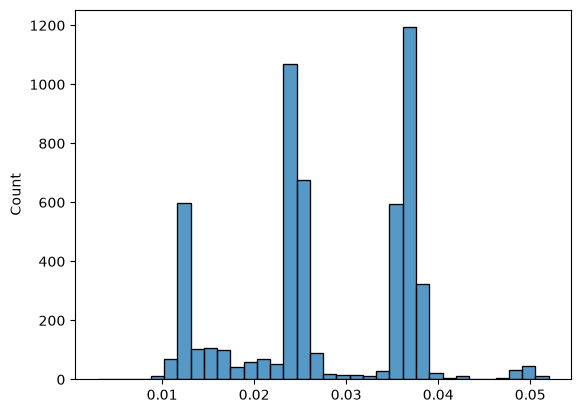

In [45]:
sns.histplot(squeezed_intervals);

The repeat intervals are short and regular: 3–52 ms, about 28 ms on average (roughly 36 repeats per second), which is typical for keyboard auto-repeat. The histogram has peaks at about 12, 25 and 37 ms, i.e. multiples of roughly 12 ms, the same as the base interval between mouse events. The logger seems to record events on a ~12 ms tick; if so, timings are only precise to about 12 ms, despite the microsecond timestamps.

**Conclusion:** the repeated `pressed` events are auto-repeat, so merging them into one physical press is correct. A key's dwell time runs from its first `pressed` event to its `released` event.

### Presses without a release

Which keys have a press without a release (no `Up` time)?

In [46]:
orphans_df = key_df[key_df["Up"].isna()]
orphans_df["Key"].unique()

<ArrowStringArray>
['tab']
Length: 1, dtype: str

In [47]:
tab_only_df = key_df[key_df["Key"] == "tab"]
tab_only_df.isna().sum()

Key                0
Down               0
Epochs             0
Up              3169
Release Only      19
dtype: int64

Only `tab`. It has 3,188 presses, of which 3,169 are release-only (no `pressed` event was logged) and only 19 have both events. This confirms the EDA finding that the `tab` key-down is almost never logged. Release-only rows have no real `Down` time (it is set to the release time), so their dwell time is undefined (`NaN`).

## 6. Keyboard features on the cleaned events

### Timing features

For each press I take the next press in the same attempt and compute the standard keystroke timings:
- `Dwell Time` = `Up − Down`: how long the key was held;
- `Flight Time` = next `Down` − `Up`: from the release to the next press, as in the paper. It is negative when the next key goes down before this one is released (rollover);
- `DD` = next `Down` − `Down`: press-to-press latency;
- `UU` = next `Up` − `Up`: release-to-release latency.

In [48]:
next_key_df = key_df.groupby(level=LEVELS).shift(-1).rename({
    "Key": "Next Key",
    "Down": "Next Down",
    "Up": "Next Up"
    }, axis=1)

next_key_df = key_df.join(next_key_df[["Next Key", "Next Down", "Next Up"]])
next_key_df.head()

Key          Down                Epochs  \
User ID Is Genuine Test ID                                                   
1       False      1       0     shift  1.644176e+09  [1644175533.9525526]   
                           1         m  1.644176e+09  [1644175534.0420332]   
                           2         r  1.644176e+09   [1644175534.257084]   
                           3         s  1.644176e+09  [1644175534.4087963]   
                           4  spacebar  1.644176e+09  [1644175534.5358133]   

                                        Up Release Only  Next Key  \
User ID Is Genuine Test ID                                          
1       False      1       0  1.644176e+09          NaN         m   
                           1  1.644176e+09          NaN         r   
                           2  1.644176e+09          NaN         s   
                           3  1.644176e+09          NaN  spacebar   
                           4  1.644176e+09          NaN    rshift   

                                 Next Down       Next Up  
User ID Is Genuine Test ID                                
1       False      1       0  1.644176e+09  1.644176e+09  
                           1  1.644176e+09  1.644176e+09  
                           2  1.644176e+09  1.644176e+09  
                           3  1.644176e+09  1.644176e+09  
                           4  1.644176e+09  1.644176e+09

In [49]:
featured_key_df = next_key_df.copy()

featured_key_df["Dwell Time"] = featured_key_df["Up"] - featured_key_df["Down"]
featured_key_df["UU"] = featured_key_df["Next Up"] - featured_key_df["Up"]
featured_key_df["DD"] = featured_key_df["Next Down"] - featured_key_df["Down"]
featured_key_df["Flight Time"] = featured_key_df["Next Down"] - featured_key_df["Up"]

featured_key_df.head()

Key          Down                Epochs  \
User ID Is Genuine Test ID                                                   
1       False      1       0     shift  1.644176e+09  [1644175533.9525526]   
                           1         m  1.644176e+09  [1644175534.0420332]   
                           2         r  1.644176e+09   [1644175534.257084]   
                           3         s  1.644176e+09  [1644175534.4087963]   
                           4  spacebar  1.644176e+09  [1644175534.5358133]   

                                        Up Release Only  Next Key  \
User ID Is Genuine Test ID                                          
1       False      1       0  1.644176e+09          NaN         m   
                           1  1.644176e+09          NaN         r   
                           2  1.644176e+09          NaN         s   
                           3  1.644176e+09          NaN  spacebar   
                           4  1.644176e+09          NaN    rshift   

                                 Next Down       Next Up  Dwell Time  \
User ID Is Genuine Test ID                                             
1       False      1       0  1.644176e+09  1.644176e+09    0.201804   
                           1  1.644176e+09  1.644176e+09    0.062926   
                           2  1.644176e+09  1.644176e+09    0.063342   
                           3  1.644176e+09  1.644176e+09    0.100993   
                           4  1.644176e+09  1.644176e+09    0.075246   

                                    UU        DD  Flight Time  
User ID Is Genuine Test ID                                     
1       False      1       0 -0.049397  0.089481    -0.112323  
                           1  0.215467  0.215051     0.152125  
                           2  0.189364  0.151712     0.088371  
                           3  0.101269  0.127017     0.026024  
                           4  0.315332  0.176681     0.101435

### Habit counts and attempt-level timing

The `capslock`, `enter` and `spacebar` counts are recomputed on the cleaned presses, so each physical press counts once, however long the key was held.

In [50]:
other_key_df = featured_key_df[featured_key_df["Key"].isin(["capslock", "enter", "spacebar"])]
other_keys_test_level = other_key_df.groupby([
    pd.Grouper(level="User ID"),
    pd.Grouper(level="Is Genuine"),
    pd.Grouper(level="Test ID"),
    "Key"
    ])["Up"].count().unstack()
other_keys_test_level

Key                         capslock  enter  spacebar
User ID Is Genuine Test ID                           
1       False      1             NaN    NaN       2.0
                   2             NaN    NaN       2.0
                   3             8.0    NaN       2.0
                   4             NaN    NaN       2.0
                   5             NaN    NaN       2.0
...                              ...    ...       ...
88      True       6             NaN    NaN       2.0
                   7             NaN    NaN       3.0
                   8             NaN    NaN       2.0
                   9             2.0    NaN       2.0
                   10            NaN    NaN       2.0

[1759 rows x 3 columns]

Per attempt, I summarize dwell and flight times with the median and the IQR instead of the mean and standard deviation. Flight time includes the long pauses between form fields, and a few such pauses would dominate the mean.

In [51]:
key_test_level = featured_key_df.groupby(level=LEVELS).agg(
    Dwell_median=("Dwell Time", "median"),
    Dwell_iqr=("Dwell Time", lambda x: x.quantile(.75) - x.quantile(.25)),
    Flight_median=("Flight Time", "median"),
    Flight_iqr=("Flight Time", lambda x: x.quantile(.75) - x.quantile(.25)),
    DD_median=("DD", "median"),
    DD_iqr=("DD", lambda x: x.quantile(.75) - x.quantile(.25)),
    UU_median=("UU", "median"),
    UU_iqr=("UU", lambda x: x.quantile(.75) - x.quantile(.25))
)
key_test_level

Dwell_median  Dwell_iqr  Flight_median  \
User ID Is Genuine Test ID                                           
1       False      1            0.075183   0.024578       0.152125   
                   2            0.086801   0.014753       0.379757   
                   3            0.073625   0.025564       0.127848   
                   4            0.121413   0.021379       0.085070   
                   5            0.170910   0.049758       0.060691   
...                                  ...        ...            ...   
88      True       6            0.142035   0.059016       0.224558   
                   7            0.141037   0.053761       0.336086   
                   8            0.141034   0.053261       0.399101   
                   9            0.141034   0.059767       0.540136   
                   10           0.147538   0.066015       0.487123   

                            Flight_iqr  DD_median    DD_iqr  UU_median  \
User ID Is Genuine Test ID                                               
1       False      1          0.231739   0.215051  0.294208   0.216582   
                   2          0.552763   0.480338  0.689027   0.468952   
                   3          0.405288   0.206717  0.433331   0.187322   
                   4          0.805698   0.220963  0.819443   0.206442   
                   5          0.299547   0.237161  0.484073   0.184446   
...                                ...        ...       ...        ...   
88      True       6          0.871720   0.556635  0.930741   0.339085   
                   7          0.999254   0.503129  0.974750   0.475123   
                   8          0.674176   0.583142  0.811207   0.411105   
                   9          0.858222   0.705179  0.978251   0.667169   
                   10         0.644160   0.577149  0.799200   0.602152   

                              UU_iqr  
User ID Is Genuine Test ID            
1       False      1        0.320033  
                   2        0.786050  
                   3        0.421998  
                   4        1.025717  
                   5        0.218457  
...                              ...  
88      True       6        0.934233  
                   7        1.026763  
                   8        0.534146  
                   9        0.817210  
                   10       0.490124  

[1760 rows x 8 columns]

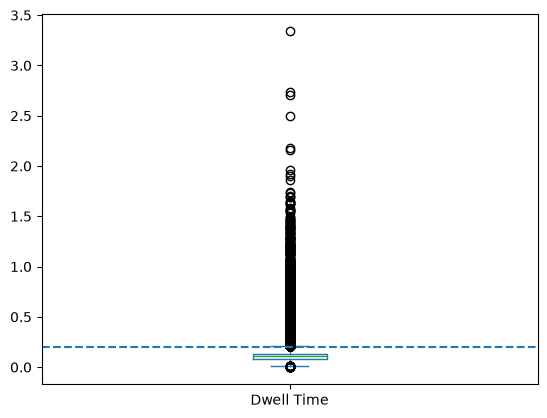

In [52]:
ax = featured_key_df["Dwell Time"].plot(kind="box")
plt.axhline(0.2, linestyle="--", label="0.3 s");

After cleaning, most dwell times lie between about 0.08 and 0.13 s. The long tail remains (up to more than 3 s), now including the full hold time of auto-repeated keys.

### Shift and correction keys

How long a user holds `shift` may be a habit of its own, so I compute the shift dwell statistics and count per attempt, and the same for the correction keys (`backspace`, `delete`).

In [53]:
shift_key_df = featured_key_df[featured_key_df["Key"].isin(SHIFT_KEYS)]
shift_key_features = shift_key_df.groupby(level=LEVELS).agg(
    Shift_Dwell_mean=("Dwell Time", "mean"),
    Shift_Dwell_std=("Dwell Time", "std"),
    Shift_count=("Dwell Time", "count")
)

In [54]:
correction_key_df = featured_key_df[featured_key_df["Key"].isin(CORRECTION_KEYS)]
correction_key_features = correction_key_df.groupby(level=LEVELS).agg(
    Corr_Dwell_mean=("Dwell Time", "mean"),
    Corr_Dwell_std=("Dwell Time", "std"),
    Corr_count=("Dwell Time", "count")
)

### Updated feature table

The updated table replaces the keyboard timings with the cleaned ones (`Dwell_median`, `Dwell_iqr`, `Flight_median`, `Flight_iqr`), adds `DD` and `UU` timings and uses the recomputed `capslock`, `enter` and `spacebar` counts. The mouse features and the other counts are unchanged from sections 1–3. The shift and correction-key features from the previous two cells are not included yet.

In [55]:
test_level_features = (
    key_test_level
    .join(test_level_clicks)
    .join(movement_test_level_features)
    .join(other_keys_test_level)
    .join(tab_test_level)
    .join(correction_keys_test_level)
    .join(numpad_keys_test_level)
    .join(arrow_keys_test_level)
)
test_level_features.fillna({
    "enter": 0,
    "spacebar": 0,
    "tab": 0,
    "capslock": 0,
    "arrows": 0,
    "numpad": 0,
    "delete": 0,
    "backspace": 0
}, inplace=True)
test_level_features

Dwell_median  Dwell_iqr  Flight_median  \
User ID Is Genuine Test ID                                           
1       False      1            0.075183   0.024578       0.152125   
                   2            0.086801   0.014753       0.379757   
                   3            0.073625   0.025564       0.127848   
                   4            0.121413   0.021379       0.085070   
                   5            0.170910   0.049758       0.060691   
...                                  ...        ...            ...   
88      True       6            0.142035   0.059016       0.224558   
                   7            0.141037   0.053761       0.336086   
                   8            0.141034   0.053261       0.399101   
                   9            0.141034   0.059767       0.540136   
                   10           0.147538   0.066015       0.487123   

                            Flight_iqr  DD_median    DD_iqr  UU_median  \
User ID Is Genuine Test ID                                               
1       False      1          0.231739   0.215051  0.294208   0.216582   
                   2          0.552763   0.480338  0.689027   0.468952   
                   3          0.405288   0.206717  0.433331   0.187322   
                   4          0.805698   0.220963  0.819443   0.206442   
                   5          0.299547   0.237161  0.484073   0.184446   
...                                ...        ...       ...        ...   
88      True       6          0.871720   0.556635  0.930741   0.339085   
                   7          0.999254   0.503129  0.974750   0.475123   
                   8          0.674176   0.583142  0.811207   0.411105   
                   9          0.858222   0.705179  0.978251   0.667169   
                   10         0.644160   0.577149  0.799200   0.602152   

                              UU_iqr  Burst_count  Dwell_Time_mean  ...  \
User ID Is Genuine Test ID                                          ...   
1       False      1        0.320033            0         0.102698  ...   
                   2        0.786050            0         0.133980  ...   
                   3        0.421998            0         0.095714  ...   
                   4        1.025717            0         0.220024  ...   
                   5        0.218457            0         0.167220  ...   
...                              ...          ...              ...  ...   
88      True       6        0.934233            0         0.227391  ...   
                   7        1.026763            0         0.229058  ...   
                   8        0.534146            0         0.224055  ...   
                   9        0.817210            0         0.217556  ...   
                   10       0.490124            0         0.223543  ...   

                             Jerk_min_mean  Jerk_plus_mean  capslock  enter  \
User ID Is Genuine Test ID                                                    
1       False      1       -4830879.387616  4603405.381208       0.0    0.0   
                   2       -3493473.695546  2988733.176243       0.0    0.0   
                   3       -5594145.315441  5780988.700273       8.0    0.0   
                   4       -3026919.551201  3722555.070636       0.0    0.0   
                   5        -10917781.4193  65237131.70116       0.0    0.0   
...                                    ...             ...       ...    ...   
88      True       6       -3223737.183462  3323694.382334       0.0    0.0   
                   7       -6565467.126815  4332449.401313       0.0    0.0   
                   8       -3197003.467331  2332595.348334       0.0    0.0   
                   9       -3076859.863097  2640868.598607       2.0    0.0   
                   10        -4464797.9443  3044390.516332       0.0    0.0   

                            spacebar  tab  backspace  delete  numpad  arrows  
User ID Is Genuine Test ID                                             

In [56]:
X = [test_level_features.loc[(user_id)] for user_id in range(1, 89)]
y = [test_level_features.loc[(user_id)].index.get_level_values("Is Genuine") for user_id in range(1, 89)]

### Re-evaluation

Logistic regression with stratified 5-fold CV on the updated table, which reached 0.861 ± 0.090 (vs 0.842 ± 0.094 with the first-pass features).

In [57]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.base import clone

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(),
)

scores = []
for user_id in range(1,89):
    score = cross_val_score(
        model,
        X[user_id-1],
        y[user_id-1],
        cv=cv,
        n_jobs=1
    )
    scores.append(score.mean())

np.mean(scores), np.std(scores)

(np.float64(0.8613636363636363), np.float64(0.09036770614577747))

The same cross-validation for an RBF SVC with `gamma="auto"` and `C=3` gives 0.859 ± 0.078, on par with logistic regression.

In [58]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    SVC(kernel="rbf", gamma="auto", C=3),
)

scores = []
for user_id in range(1,89):
    score = cross_val_score(
        model,
        X[user_id-1],
        y[user_id-1],
        cv=cv,
        n_jobs=1
    )
    scores.append(score.mean())

np.mean(scores), np.std(scores)

(np.float64(0.859090909090909), np.float64(0.0778056489482895))

## Summary

- Cleaning the keyboard events (merging auto-repeats into physical presses and flagging release-only `tab` events) makes the keyboard timings match their definitions: dwell time now covers the whole hold, and flight time is measured from release to the next press, as in the paper.
- With the updated features, per-user logistic regression reaches 0.861 mean accuracy in 5-fold CV. The paper's decision tree reaches 75.85% on a single 80/20 split with three features.
- Accuracy on 20 attempts per user is a coarse metric. The next step, in `models.ipynb`, is evaluation with biometric metrics (ROC, EER) and a realistic enrollment protocol, where a user's template is built from their genuine attempts only.